# Town-level average monthly rent over time

This notebook aggregates the labelled training rentals by approval month and town, then shows a separate time-series plot for every town.

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

configured_root = os.environ.get('KDDM_PROJECT_ROOT')
candidate_roots = ([Path(configured_root)] if configured_root else []) + [
    Path.cwd(), *Path.cwd().parents, Path('/content/KDDM-project'),
    Path('/content/drive/MyDrive/KDDM-project'),
]
project_root = next((path for path in candidate_roots if (path / 'data/train.csv').exists()), None)
if project_root is None:
    raise FileNotFoundError('Set KDDM_PROJECT_ROOT to the project directory.')

experiment_dir = project_root / 'exploration' / 'metul'
sys.path.insert(0, str(experiment_dir))
from preprocessing import categorical_clean, load_datasets

_, datasets = load_datasets(project_root / 'data')
rentals = categorical_clean(datasets['train'].copy(), columns=['TOWN'], context='town time series', log=False)
rentals['month'] = pd.to_datetime(rentals['RENT_APPROVAL_DATE'] + '-01')
rentals['MONTHLY_RENT'] = pd.to_numeric(rentals['MONTHLY_RENT'], errors='coerce')
rentals = rentals.dropna(subset=['month', 'TOWN', 'MONTHLY_RENT'])


In [2]:
town_monthly_average = (
    rentals.groupby(['TOWN', 'month'], as_index=False)
    .agg(average_rent=('MONTHLY_RENT', 'mean'), listing_count=('MONTHLY_RENT', 'size'))
    .sort_values(['TOWN', 'month'])
)
display(town_monthly_average.head())
print(
    f'{town_monthly_average["TOWN"].nunique()} towns; '
    f'{town_monthly_average["month"].min():%b %Y} to {town_monthly_average["month"].max():%b %Y}.'
)


,TOWN,month,average_rent,listing_count
0,ang mo kio,2021-01-01,1942.055556,180
1,ang mo kio,2021-02-01,1931.517241,145
2,ang mo kio,2021-03-01,1953.411483,209
3,ang mo kio,2021-04-01,1924.759740,154
4,ang mo kio,2021-05-01,1952.227488,211


26 towns; Jan 2021 to Mar 2025.


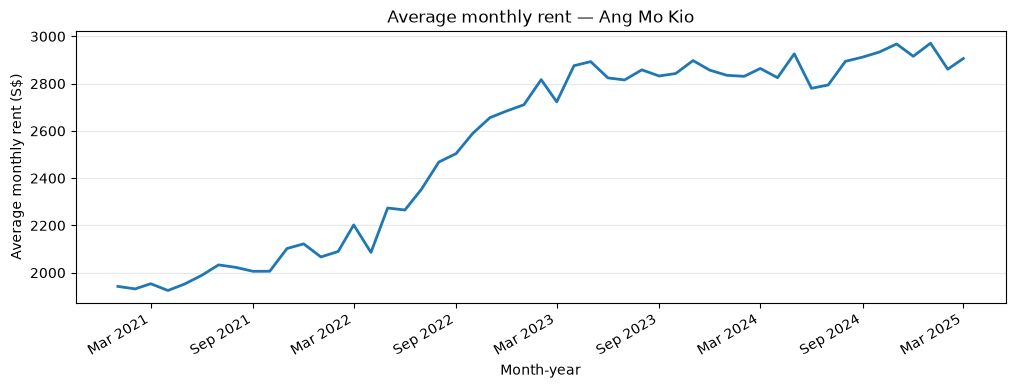

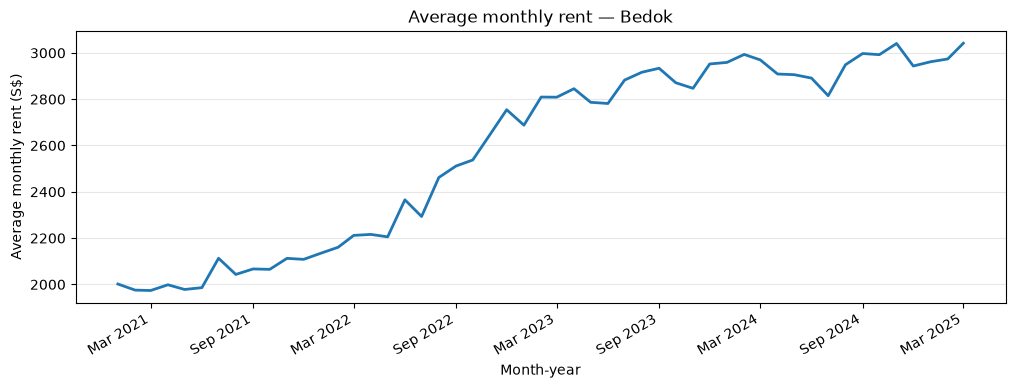

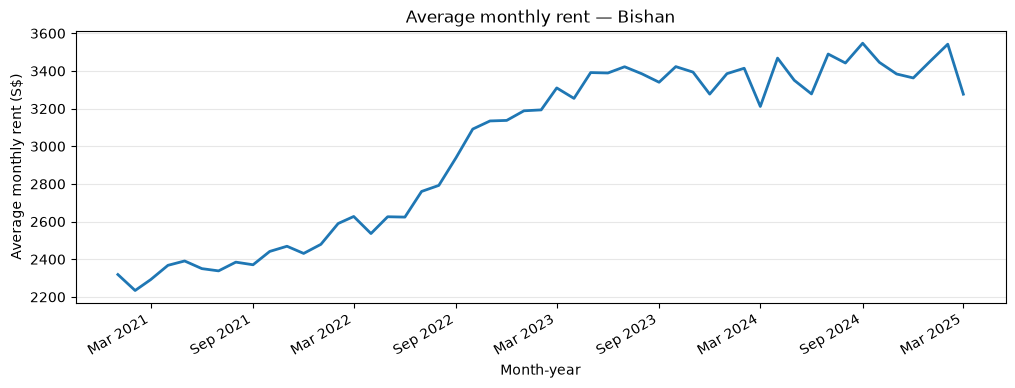

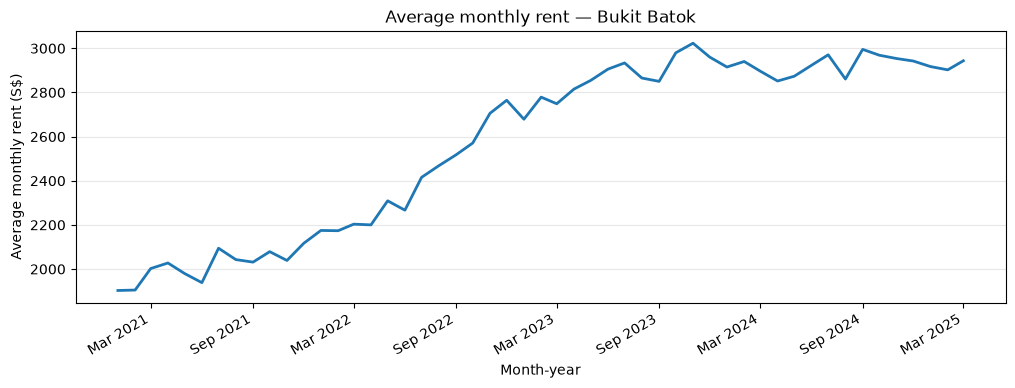

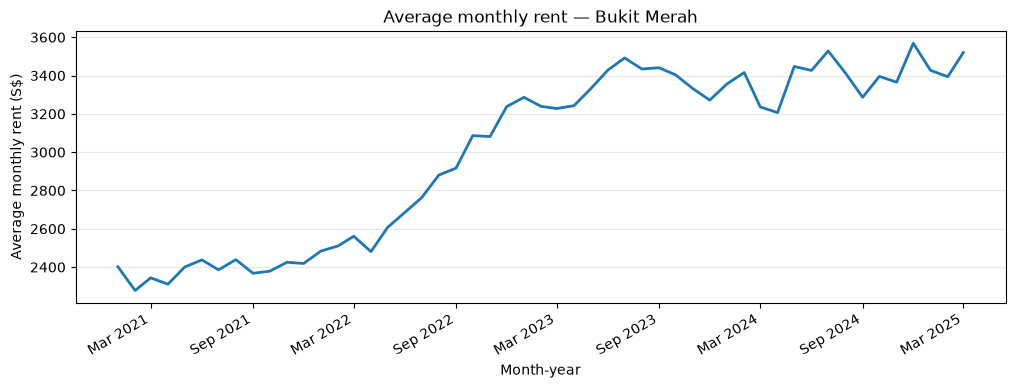

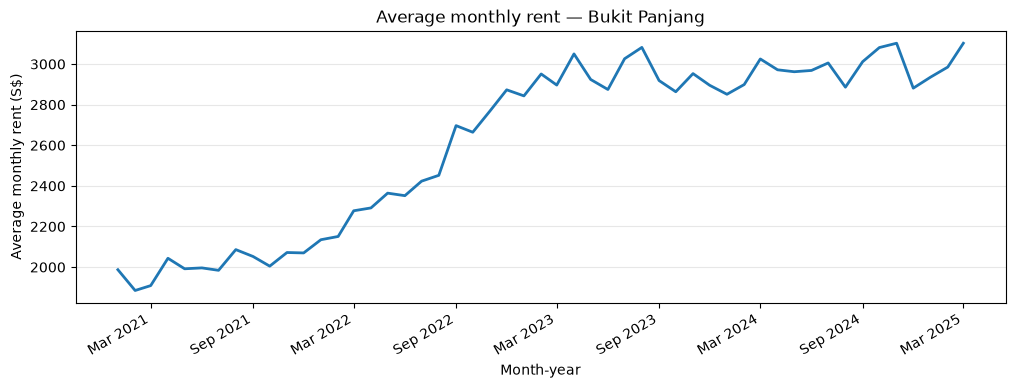

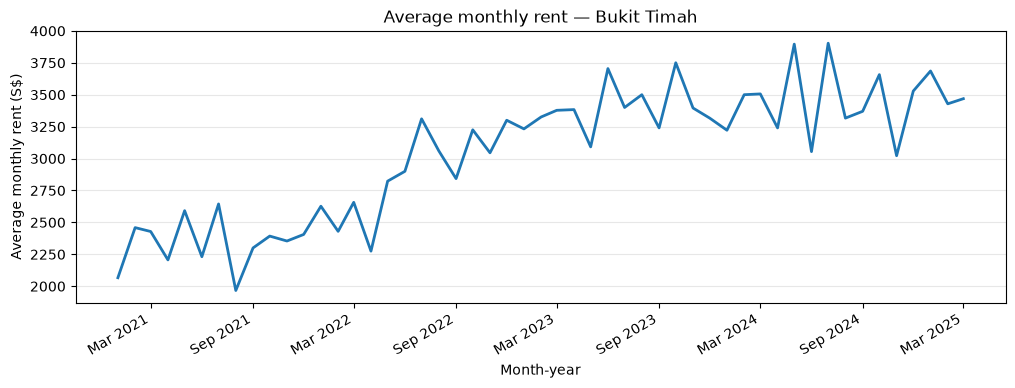

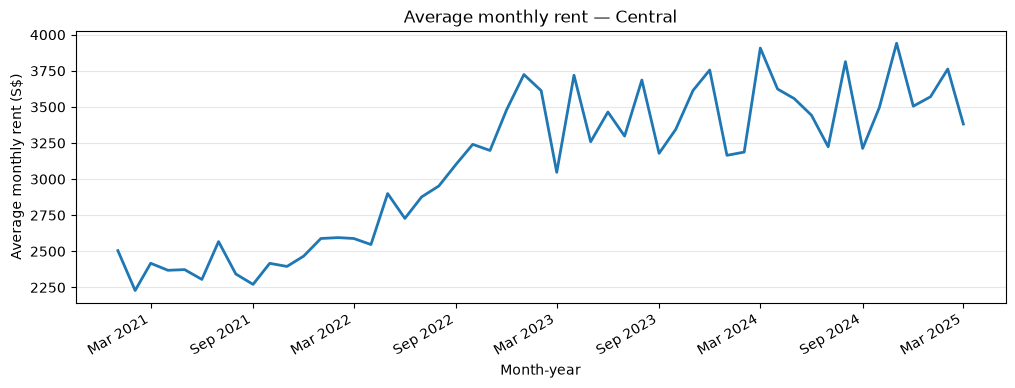

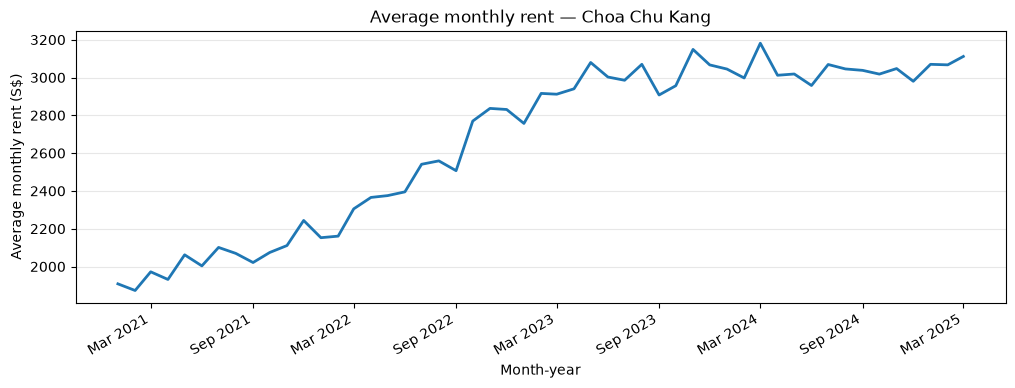

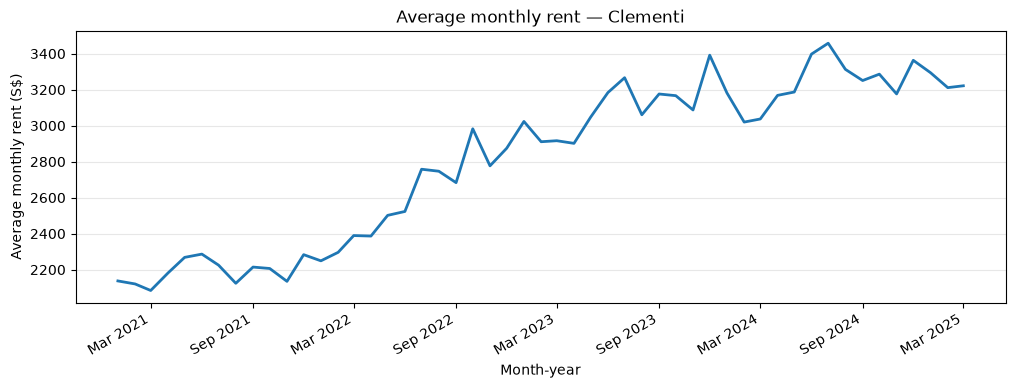

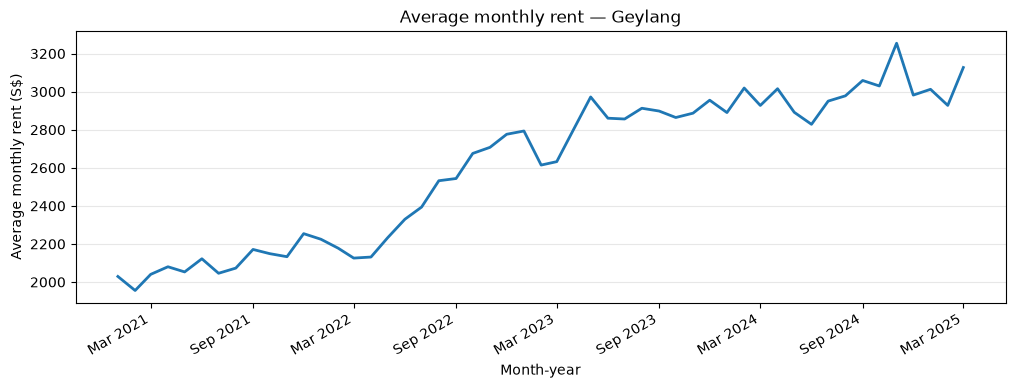

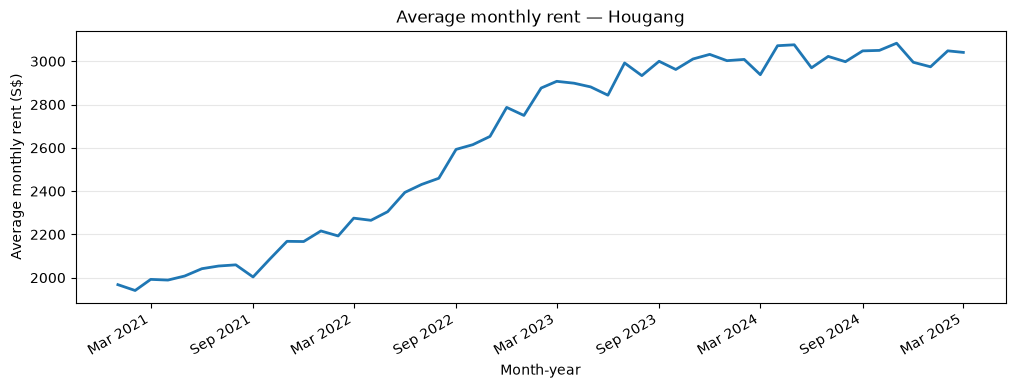

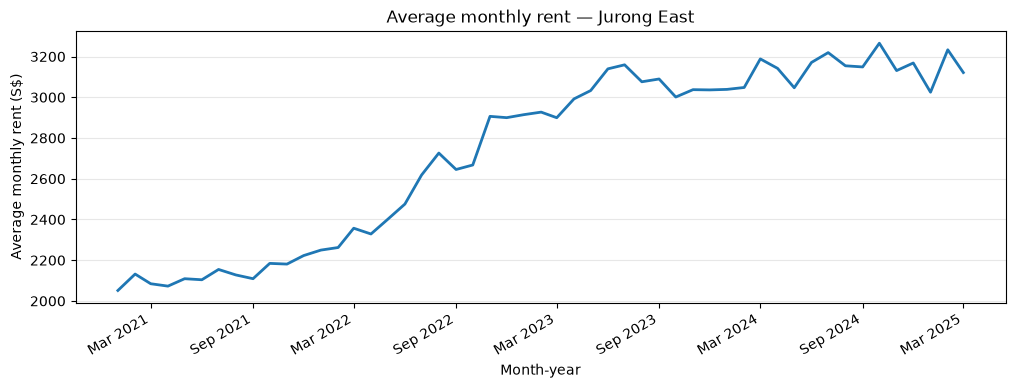

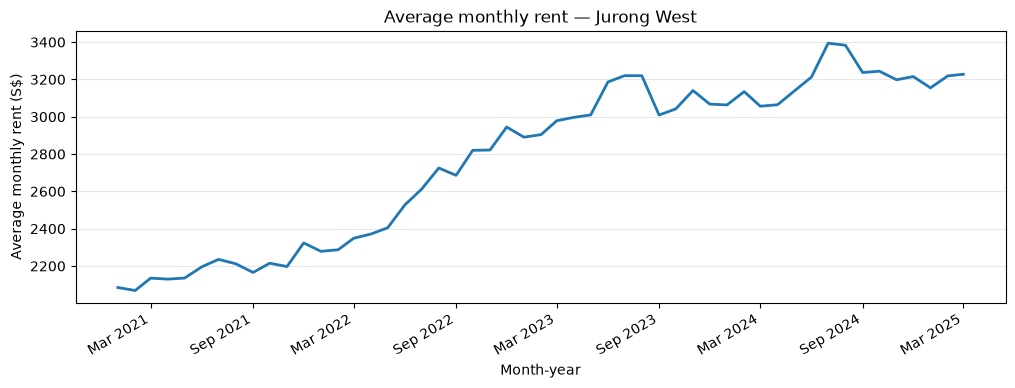

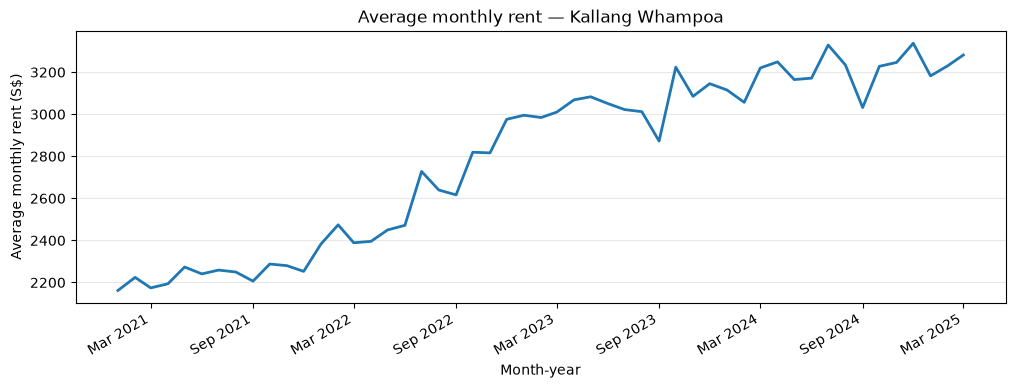

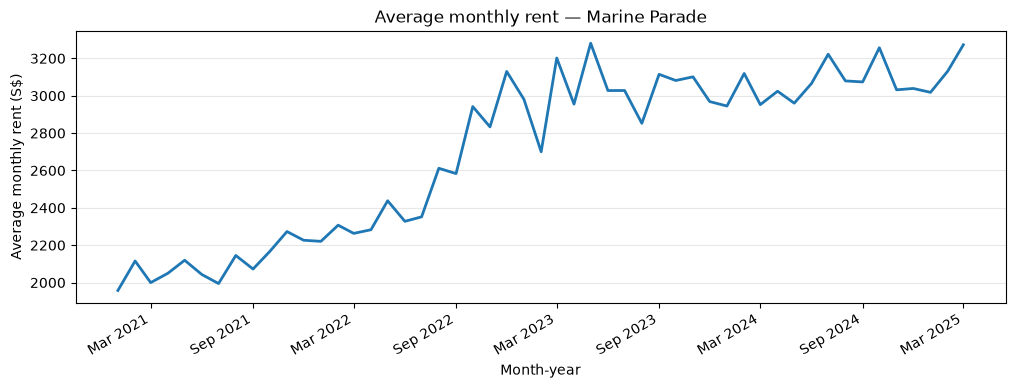

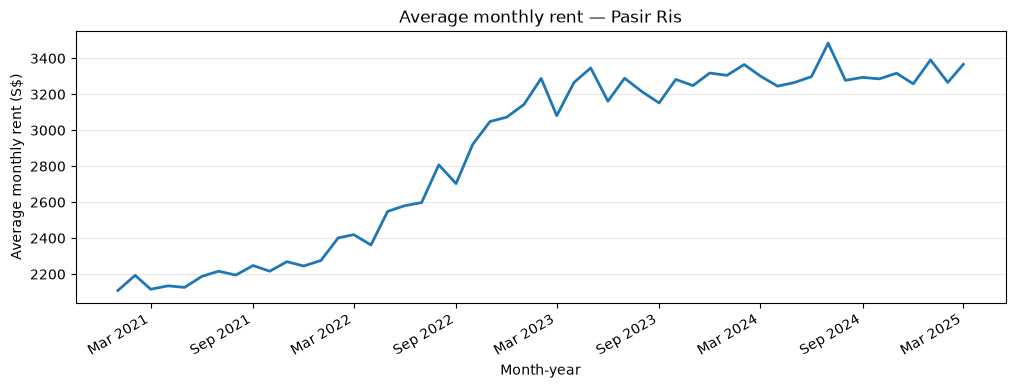

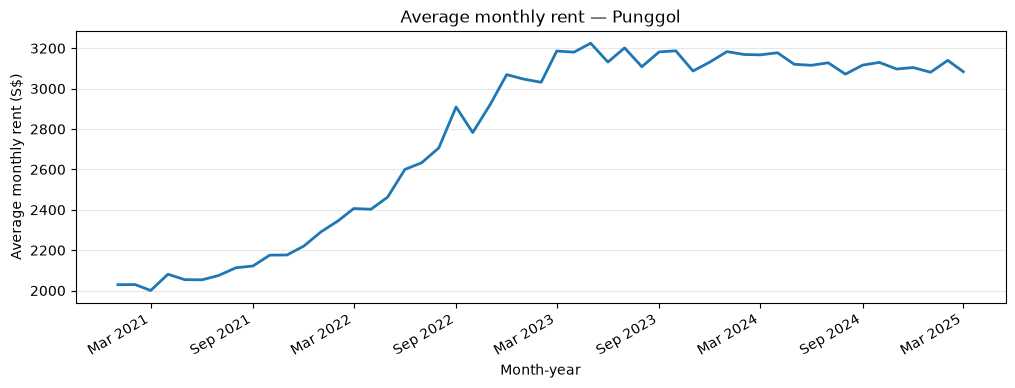

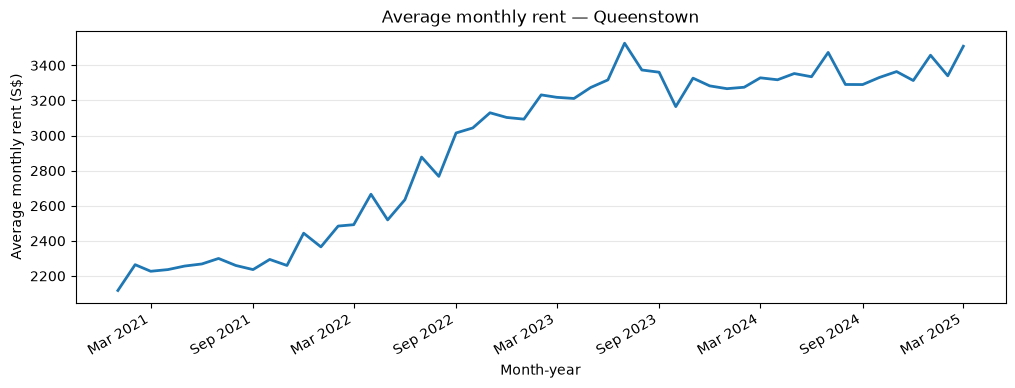

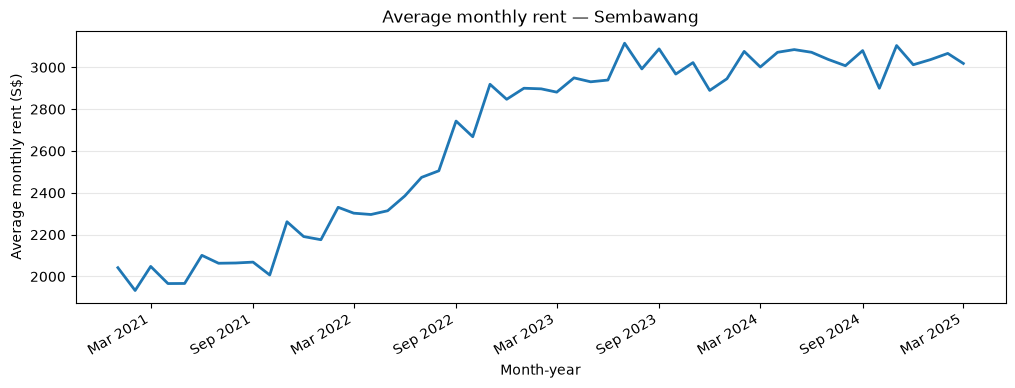

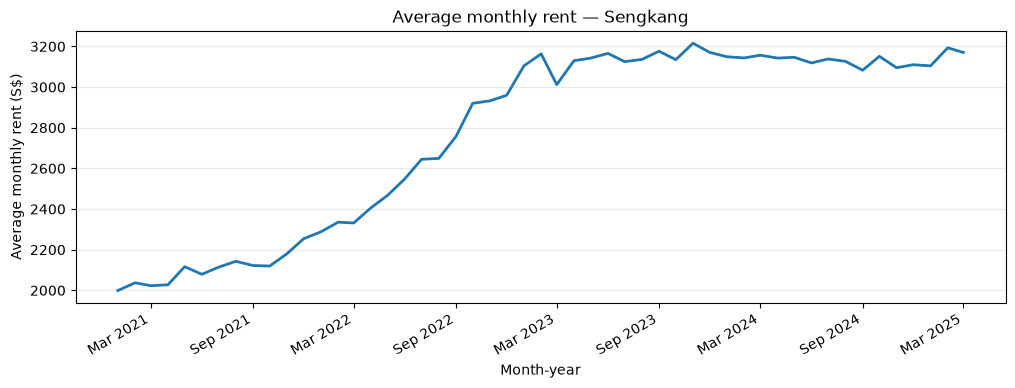

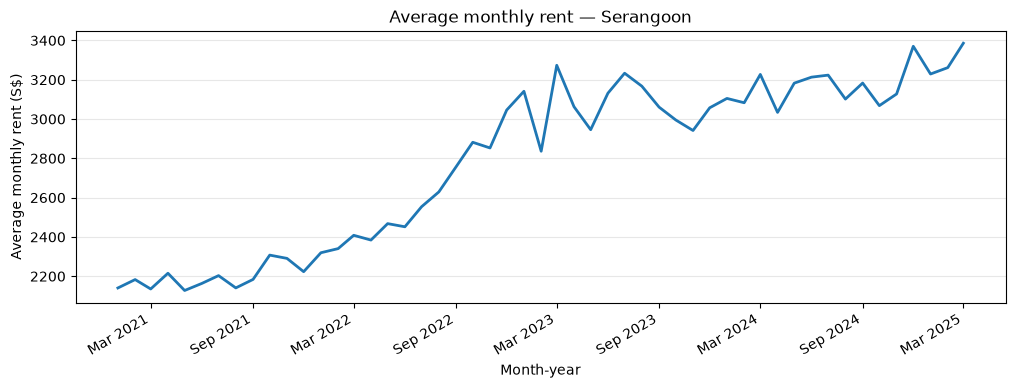

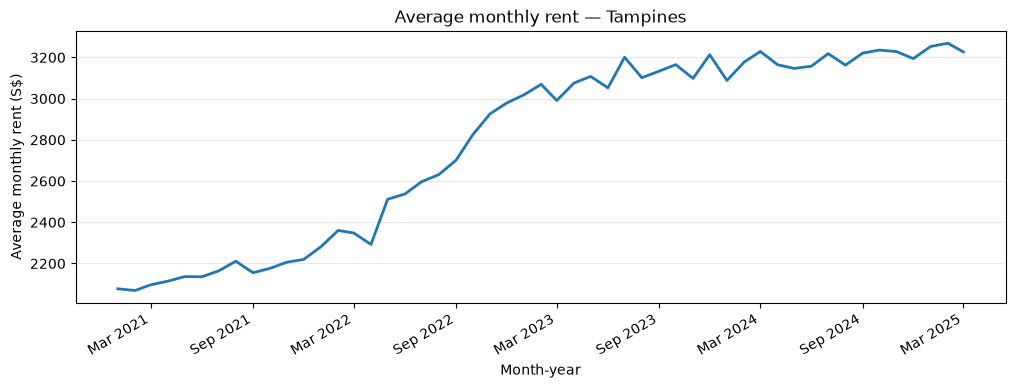

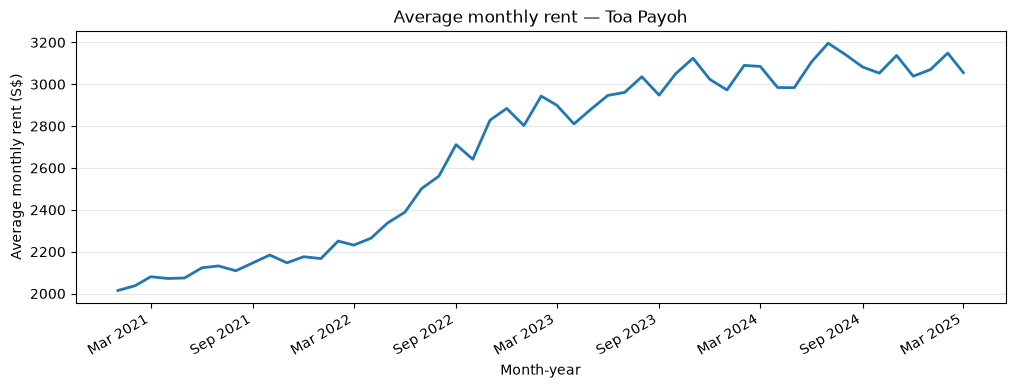

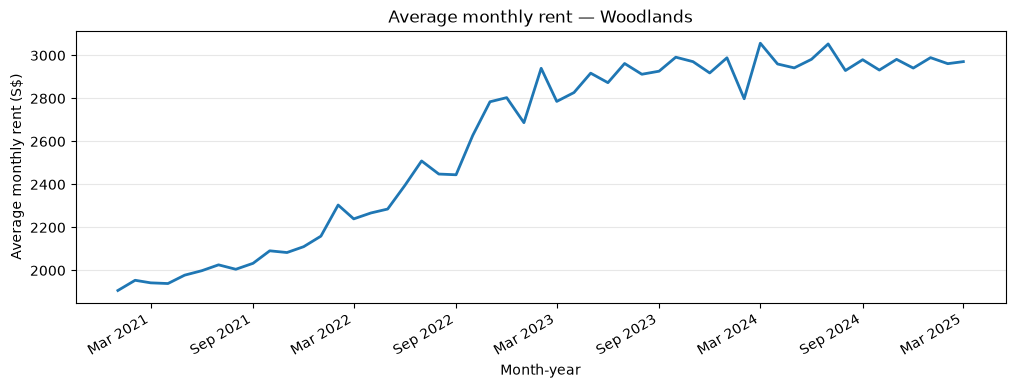

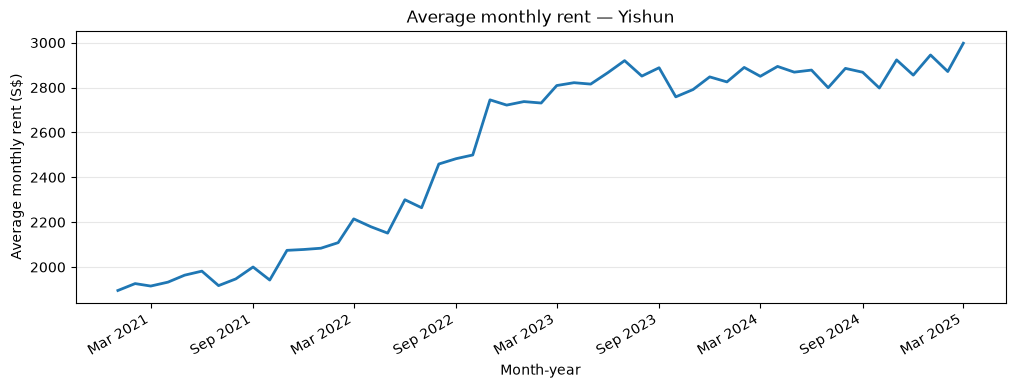

In [3]:
# One figure per town: x = approval month, y = mean rent among that town's listings.
for town, town_data in town_monthly_average.groupby('TOWN', sort=True):
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(town_data['month'], town_data['average_rent'], color='#1f77b4', linewidth=2)
    ax.set_title(f'Average monthly rent — {town.title()}')
    ax.set_xlabel('Month-year')
    ax.set_ylabel('Average monthly rent (S$)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.grid(axis='y', alpha=0.3)
    fig.autofmt_xdate()
    plt.show()
